# Image restoration with inverse and Wiener filters

**Data model.** $g(x,y) = h(x,y) * f(x,y) + n(x,y)$, or in the DFT domain $G(u,v) = H(u,v)F(u,v) + N(u,v)$.
* $f$: original image ($M\times N$, values 0-255), $g$: degraded image, $\hat f$: restored image.
* $h$: motion-blur kernel (a line of $L$ pixels at an angle), known and the same over the whole image.
* $n$: white Gaussian noise, zero mean, variance $\sigma^2$, independent of $f$. So $S_n(u,v) = \sigma^2$ (flat).
* $f$ is treated as a realisation of a wide-sense stationary random field with power spectrum $S_f(u,v)$.
* The convolution is circular (the image is periodic), so it is an exact product in the DFT domain. Section 11 drops this assumption.

**Filters.** Inverse: $\hat F = G/H$ (set to 0 where $|H|\le\varepsilon$). Wiener: $\hat F = \dfrac{H^*}{|H|^2 + S_n/S_f}\,G$, the linear filter that minimises $E[|f-\hat f|^2]$.

**Metric.** $\mathrm{MSE} = \frac{1}{MN}\sum (f-\hat f)^2$ and $\mathrm{PSNR} = 10\log_{10}(255^2/\mathrm{MSE})$ dB. PSNR is just MSE on a log scale (higher is better, +3 dB = half the MSE).

I1 (220, 220) 21.0 240.0
I2 (256, 256) 0.0 255.0


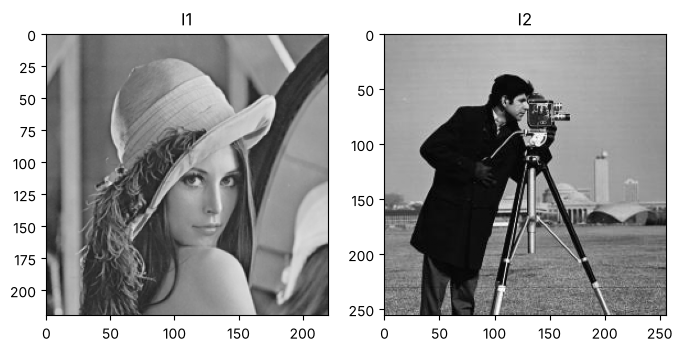

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import restoration as r

rng = np.random.default_rng(0)      # fixed seed, so the noise is the same every run
images = r.load_images("img_restoration.mat")

for name in images:
    print(name, images[name].shape, images[name].min(), images[name].max())

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(images["I1"], cmap="gray", vmin=0, vmax=255)
ax[0].set_title("I1")
ax[1].imshow(images["I2"], cmap="gray", vmin=0, vmax=255)
ax[1].set_title("I2")
plt.show()

In [2]:
# Helper: show a row of images with their PSNR
def show(f, results):
    fig, ax = plt.subplots(1, len(results), figsize=(4 * len(results), 4))
    for i, title in enumerate(results):
        img = results[title]
        ax[i].imshow(np.clip(img, 0, 255), cmap="gray", vmin=0, vmax=255)
        if r.mse(f, img) == 0:
            ax[i].set_title(title)              # the original itself: PSNR is infinite
        else:
            ax[i].set_title(f"{title}\nPSNR = {r.psnr(f, img):.1f} dB")
        ax[i].axis("off")
    plt.show()

## 1. Motion-blur kernel and its transfer function
A straight line of `L` pixels at angle `ANGLE`. $|H(u,v)|$ has (near-)zeros along lines perpendicular to the motion direction. At those frequencies the image information is lost, and the inverse filter would divide by almost zero.

smallest |H| = 1.9887277958885373e-18
fraction of frequencies with |H| < 0.01 = 0.03950413223140496


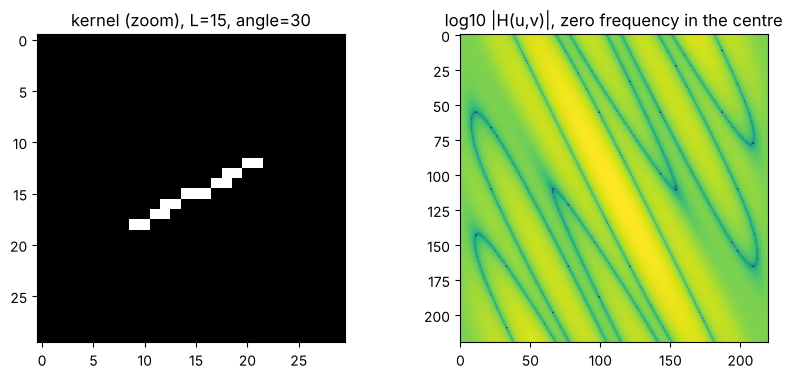

In [3]:
L = 15          # blur length in pixels
ANGLE = 30      # blur direction in degrees
SIGMA = 10      # noise standard deviation (0-255 scale)

f = images["I1"]
psf = r.motion_psf(L, ANGLE, f.shape)
H = np.fft.fft2(psf)

f2 = images["I2"]
psf2 = r.motion_psf(L, ANGLE, f2.shape)
H_2 = np.fft.fft2(psf2)

print("smallest |H| =", np.abs(H).min())
print("fraction of frequencies with |H| < 0.01 =", np.mean(np.abs(H) < 0.01))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(np.fft.fftshift(psf)[95:125, 95:125], cmap="gray")
ax[0].set_title(f"kernel (zoom), L={L}, angle={ANGLE}")
ax[1].imshow(np.log10(np.abs(np.fft.fftshift(H)) + 1e-6))
ax[1].set_title("log10 |H(u,v)|, zero frequency in the centre")
plt.show()

## 2. The three distortions

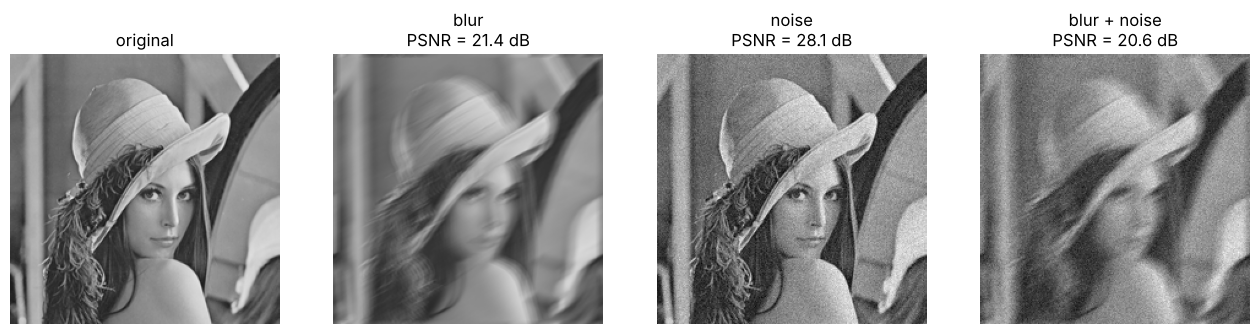

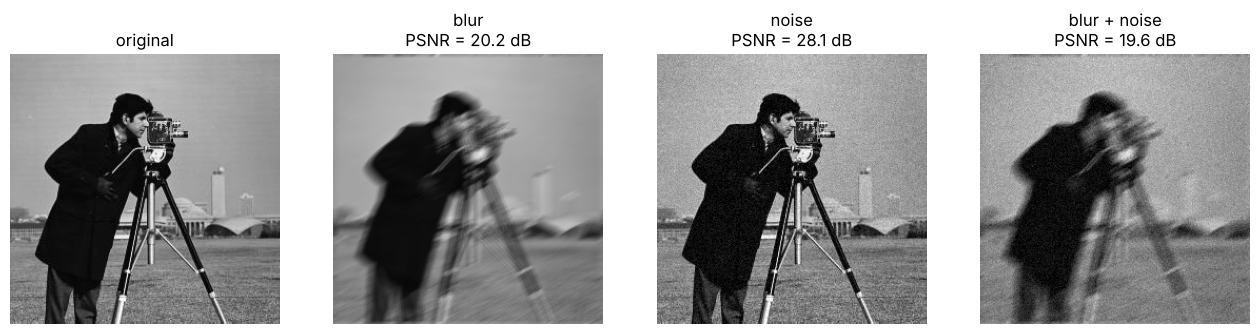

In [4]:
g_blur = r.blur(f, H)
g_noise = r.add_noise(f, SIGMA, rng)
g_both = r.add_noise(r.blur(f, H), SIGMA, rng)

g_blur2 = r.blur(f2, H_2)
g_noise2 = r.add_noise(f2, SIGMA, rng)
g_both2= r.add_noise(r.blur(f2, H_2), SIGMA, rng)

show(f, {"original": f, "blur": g_blur, "noise": g_noise, "blur + noise": g_both})
show(f2, {"original": f2, "blur": g_blur2, "noise": g_noise2, "blur + noise": g_both2})

## 3. Inverse filter
Without noise, the inverse filter gives back the original almost perfectly, **except** where $H$ is exactly zero: for I1 this kernel has a few frequencies with $|H|\approx 10^{-18}$, so even $\varepsilon = 0$ fails (division by zero amplifies rounding errors). A tiny threshold such as $\varepsilon = 0.001$ fixes it. With noise, $\hat F = F + N/H$: the noise is divided by tiny values of $H$ and explodes. A threshold $\varepsilon$ stops that, but the frequencies that are set to zero are lost.

With noise, the sweep below peaks around $\varepsilon \approx 0.3$, and even there the inverse filter is only about 1 dB better than the degraded image. Finding that optimum needs the original image, so in the later comparisons we keep the round value $\varepsilon = 0.1$; the conclusion is the same.

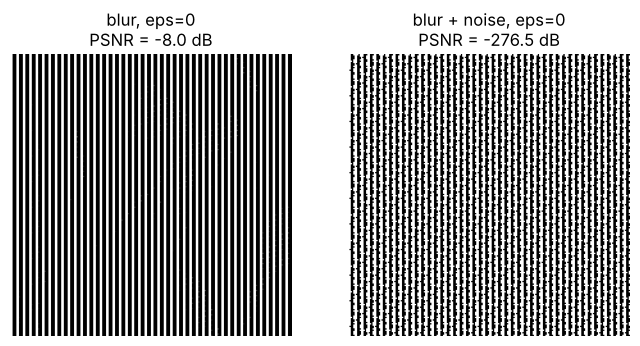

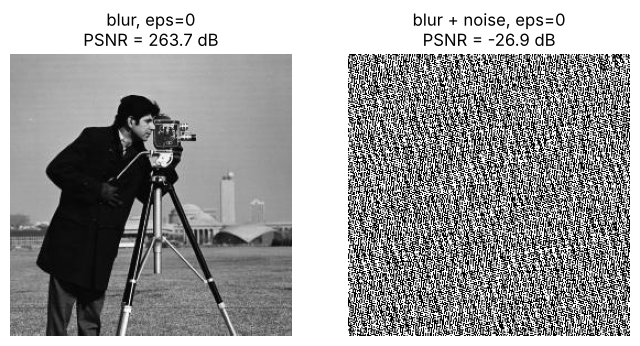

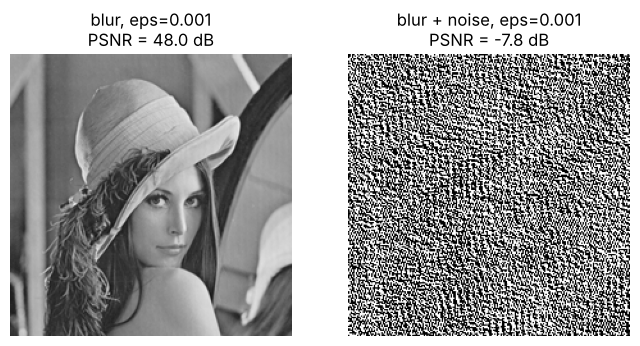

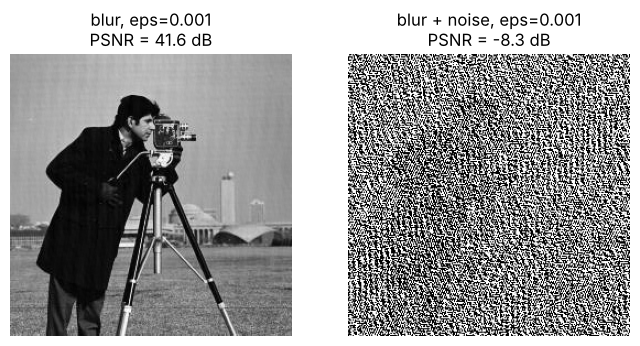

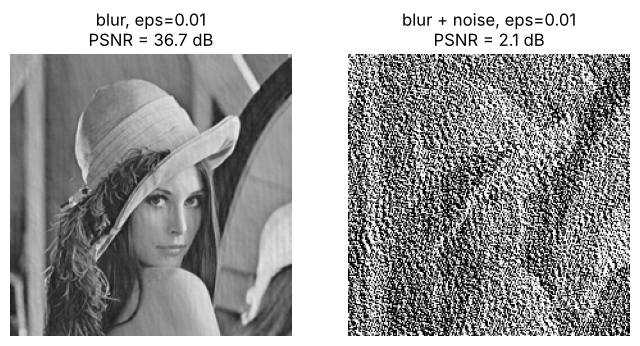

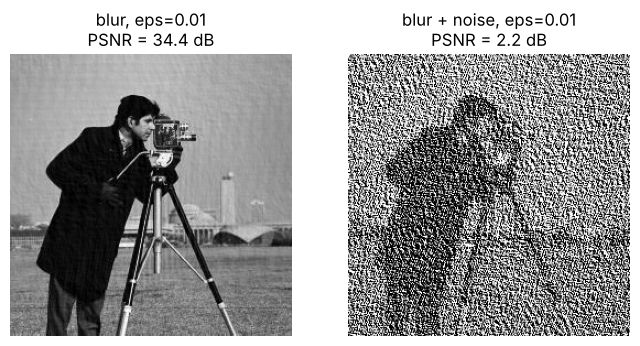

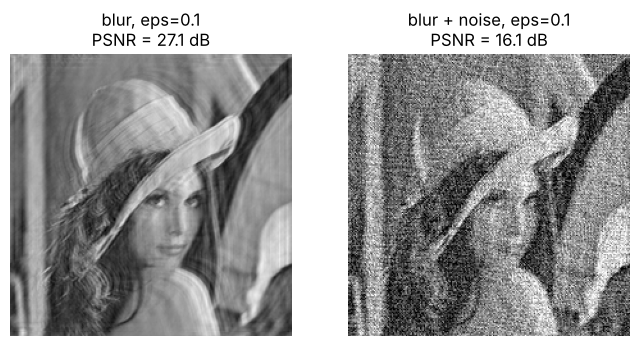

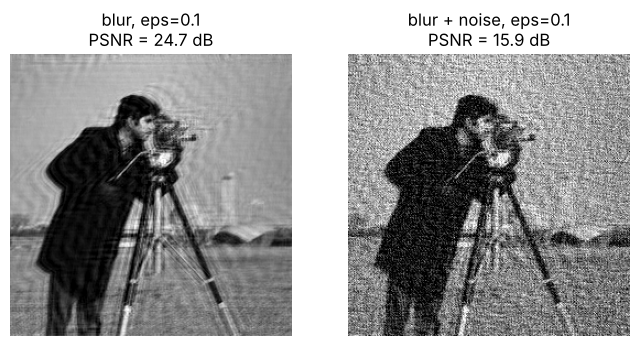

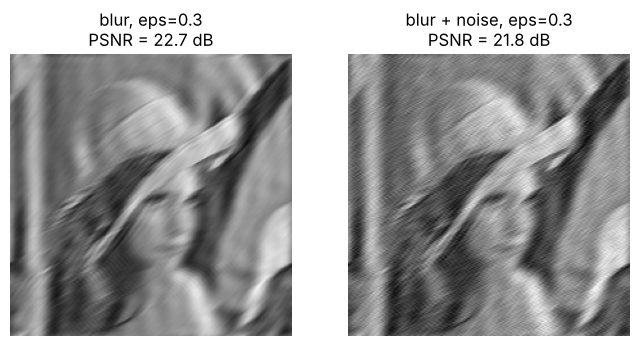

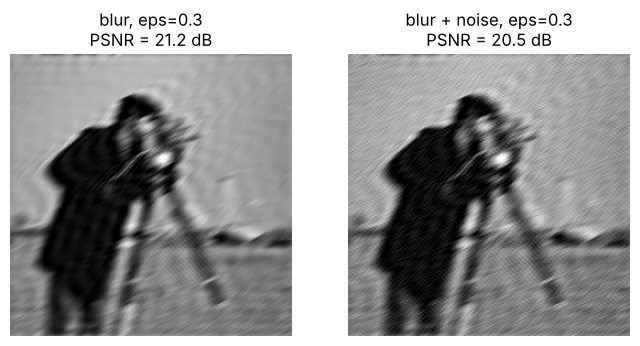

In [5]:
for eps in [0, 0.001, 0.01, 0.1, 0.3]:
    show(f, {f"blur, eps={eps}": r.inverse_filter(g_blur, H, eps),
             f"blur + noise, eps={eps}": r.inverse_filter(g_both, H, eps)})
    show(f2, {f"blur, eps={eps}": r.inverse_filter(g_blur2, H_2, eps),
                 f"blur + noise, eps={eps}": r.inverse_filter(g_both2, H_2, eps)})

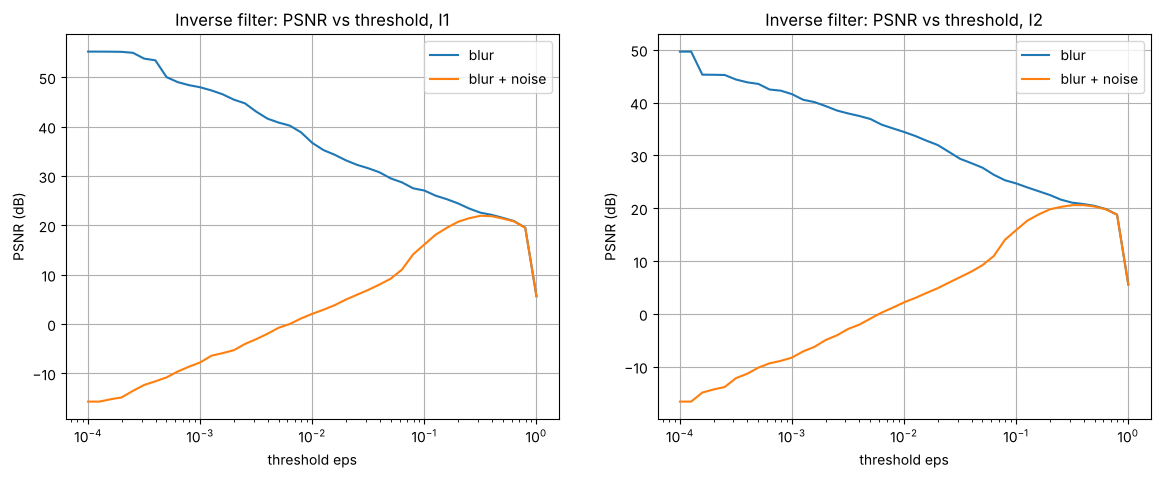

In [6]:
eps_values = np.logspace(-4, 0, 41)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for i, (f_, H_, gb, gbn, name) in enumerate([(f, H, g_blur, g_both, "I1"),
                                             (f2, H_2, g_blur2, g_both2, "I2")]):
    psnr_blur = []
    psnr_both = []
    for eps in eps_values:
        psnr_blur.append(r.psnr(f_, r.inverse_filter(gb, H_, eps)))
        psnr_both.append(r.psnr(f_, r.inverse_filter(gbn, H_, eps)))

    ax[i].semilogx(eps_values, psnr_blur, label="blur")
    ax[i].semilogx(eps_values, psnr_both, label="blur + noise")
    ax[i].set_xlabel("threshold eps")
    ax[i].set_ylabel("PSNR (dB)")
    ax[i].set_title(f"Inverse filter: PSNR vs threshold, {name}")
    ax[i].legend()
    ax[i].grid(True)
plt.show()

## 4. Wiener filter with a constant K
The simplest Wiener filter replaces $S_n/S_f$ by one number $K$. We try many values of $K$ and keep the best one. This needs the original image, so it is an optimistic result.

best K for I1 = 0.06309573444801943
best K for I2 = 0.06309573444801943


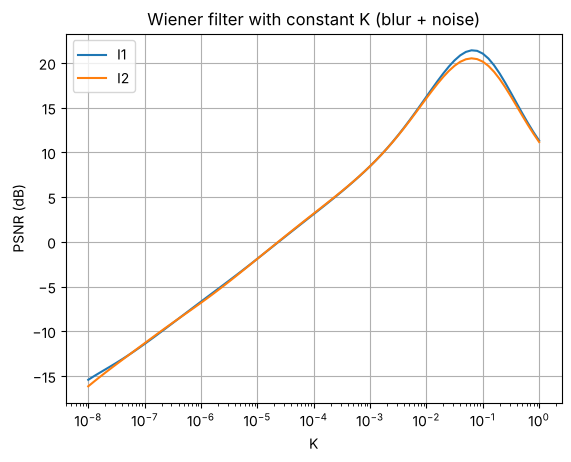

In [7]:
K_values = np.logspace(-8, 0, 81)
psnr_K = []
psnr_K2 = []
for K in K_values:
    psnr_K.append(r.psnr(f, r.wiener_filter(g_both, H, K)))
    psnr_K2.append(r.psnr(f2, r.wiener_filter(g_both2, H_2, K)))

best_K = K_values[np.argmax(psnr_K)]
best_K2 = K_values[np.argmax(psnr_K2)]
print("best K for I1 =", best_K)
print("best K for I2 =", best_K2)

plt.semilogx(K_values, psnr_K, label="I1")
plt.semilogx(K_values, psnr_K2, label="I2")
plt.xlabel("K")
plt.ylabel("PSNR (dB)")
plt.title("Wiener filter with constant K (blur + noise)")
plt.legend()
plt.grid(True)
plt.show()

## 5. Wiener filter with the true spectrum
Here $S_f = |F|^2/MN$ is computed from the original image. This is not possible in practice, but it shows the best a Wiener filter can do.

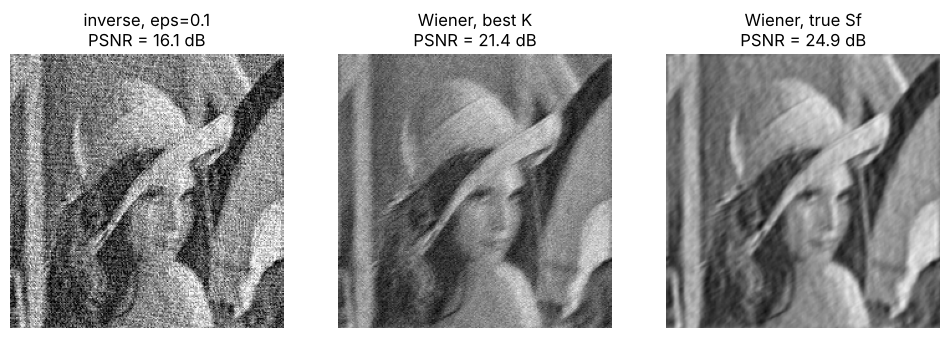

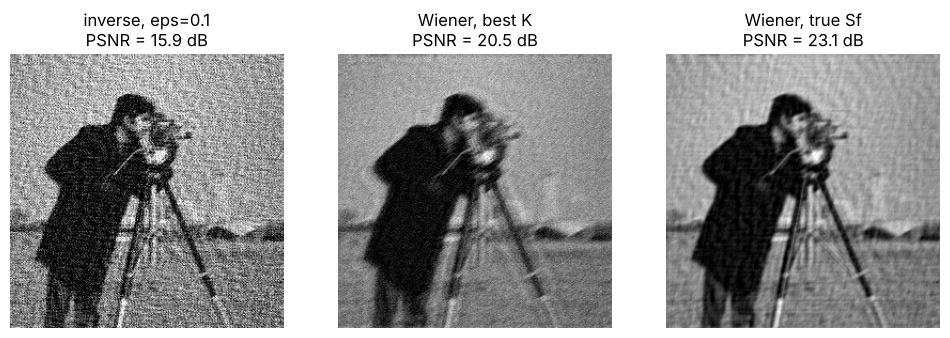

In [8]:
show(f, {"inverse, eps=0.1": r.inverse_filter(g_both, H, 0.1),
         "Wiener, best K": r.wiener_filter(g_both, H, best_K),
         "Wiener, true Sf": r.wiener_filter(g_both, H, r.true_nsr(f, SIGMA))})
show(f2, {"inverse, eps=0.1": r.inverse_filter(g_both2, H_2, 0.1),
          "Wiener, best K": r.wiener_filter(g_both2, H_2, best_K2),
          "Wiener, true Sf": r.wiener_filter(g_both2, H_2, r.true_nsr(f2, SIGMA))})

## 6. Wiener filter with $\sigma$ and $S_f$ estimated from the degraded image
In practice we only have $g$ (and $h$). We estimate both unknowns from $g$.

**Noise level.** For every $2\times2$ block, $d = (a-b-c+e)/2$. Smooth image parts cancel, so $d$ is mostly noise with variance $\sigma^2$. For Gaussian noise $\mathrm{median}(|d|) = 0.6745\,\sigma$.

**Image spectrum.** Natural images have a power-law spectrum $S_f(\rho) = A/\rho^{\alpha}$, where $\rho=\sqrt{u^2+v^2}$ is the distance to frequency 0. The degraded image has $S_g = |H|^2 S_f + \sigma^2$, so $S_f = (S_g - \sigma^2)/|H|^2$. We compute that where it is reliable and fit a straight line in $\log S_f$ vs. $\log\rho$.

**Spectrum estimate.** The raw periodogram $|G|^2/MN$ is very noisy: its standard deviation is as large as its mean, whatever the image size. Averaging each value with its $5\times5$ neighbours lowers the variance about 25 times, at the cost of frequency resolution. Since we only fit 2 numbers ($A$, $\alpha$), the lower resolution does not matter.

true sigma = 10, estimated sigma = 10.17, fitted alpha = 2.63
true sigma = 10, estimated sigma = 10.21, fitted alpha = 2.79


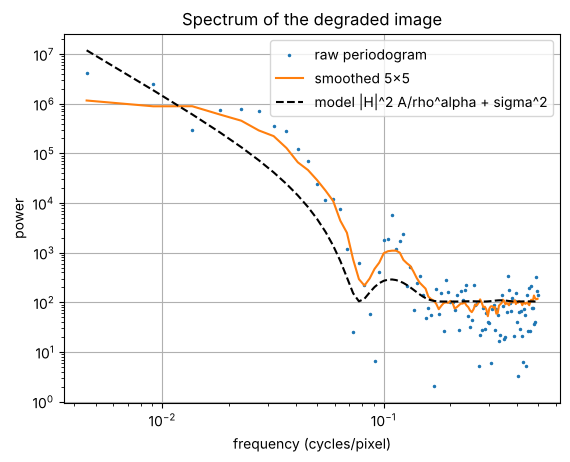

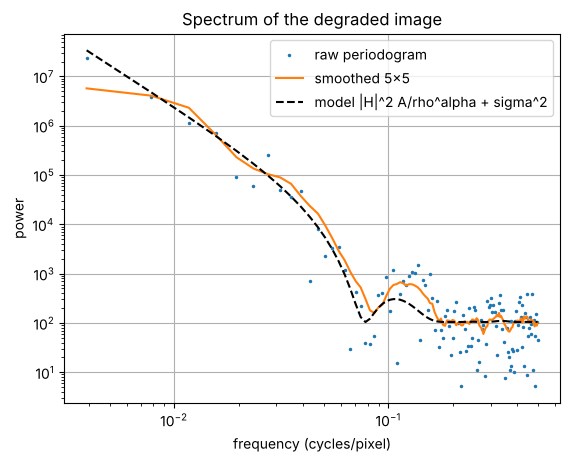

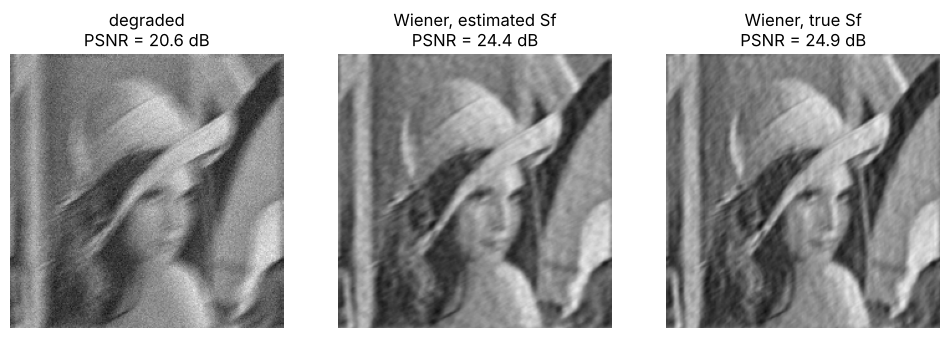

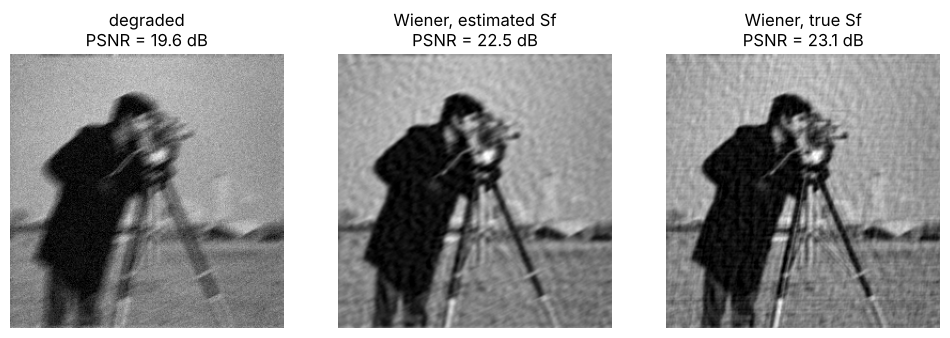

In [9]:
sigma_hat = r.estimate_sigma(g_both)
Sf_hat, alpha = r.estimate_Sf(g_both, H, sigma_hat)
print(f"true sigma = {SIGMA}, estimated sigma = {sigma_hat:.2f}, fitted alpha = {alpha:.2f}")

sigma_hat2 = r.estimate_sigma(g_both2)
Sf_hat2, alpha2 = r.estimate_Sf(g_both2, H_2, sigma_hat2)
print(f"true sigma = {SIGMA}, estimated sigma = {sigma_hat2:.2f}, fitted alpha = {alpha2:.2f}")

# Spectra along the horizontal frequency axis (first row of the DFT)
rho = r.frequency_radius(f.shape)
P_raw = r.periodogram(g_both)
rho2 = r.frequency_radius(f2.shape)
P_raw2 = r.periodogram(g_both2)
P_smooth = r.smooth_periodogram(P_raw)
P_smooth2 = r.smooth_periodogram(P_raw2)
P_model = np.abs(H) ** 2 * Sf_hat + sigma_hat ** 2
P_model2 = np.abs(H_2) ** 2 * Sf_hat2 + sigma_hat2 ** 2
half = f.shape[1] // 2
half2 = f2.shape[1] // 2

plt.loglog(rho[0, 1:half], P_raw[0, 1:half], ".", markersize=3, label="raw periodogram")
plt.loglog(rho[0, 1:half], P_smooth[0, 1:half], label="smoothed 5x5")
plt.loglog(rho[0, 1:half], P_model[0, 1:half], "k--", label="model |H|^2 A/rho^alpha + sigma^2")
plt.xlabel("frequency (cycles/pixel)")
plt.ylabel("power")
plt.title("Spectrum of the degraded image")
plt.legend()
plt.grid(True)
plt.show()

plt.loglog(rho2[0, 1:half2], P_raw2[0, 1:half2], ".", markersize=3, label="raw periodogram")
plt.loglog(rho2[0, 1:half2], P_smooth2[0, 1:half2], label="smoothed 5x5")
plt.loglog(rho2[0, 1:half2], P_model2[0, 1:half2], "k--", label="model |H|^2 A/rho^alpha + sigma^2")
plt.xlabel("frequency (cycles/pixel)")
plt.ylabel("power")
plt.title("Spectrum of the degraded image")
plt.legend()
plt.grid(True)
plt.show()

show(f, {"degraded": g_both,
         "Wiener, estimated Sf": r.wiener_filter(g_both, H, sigma_hat ** 2 / Sf_hat),
         "Wiener, true Sf": r.wiener_filter(g_both, H, r.true_nsr(f, SIGMA))})
show(f2, {"degraded": g_both2,
         "Wiener, estimated Sf": r.wiener_filter(g_both2, H_2, sigma_hat2 ** 2 / Sf_hat2),
         "Wiener, true Sf": r.wiener_filter(g_both2, H_2, r.true_nsr(f2, SIGMA))})

## 7. Results table: all distortions, both images
For "noise only" there is no blur, so $H = 1$. The inverse filter then does nothing, and the Wiener filter becomes a pure noise filter $S_f/(S_f+S_n)$.

In [10]:
print(f"{'image':<6}{'distortion':<14}{'degraded':>9}{'inverse':>9}{'W best K':>10}{'W estim.':>10}{'W true':>8}   (PSNR in dB)")

for name in images:
    f_ = images[name]
    H_blur = np.fft.fft2(r.motion_psf(L, ANGLE, f_.shape))
    H_none = np.ones(f_.shape)

    cases = [("blur", r.blur(f_, H_blur), H_blur, 0.001),
             ("noise", r.add_noise(f_, SIGMA, rng), H_none, SIGMA),
             ("blur + noise", r.add_noise(r.blur(f_, H_blur), SIGMA, rng), H_blur, SIGMA)]

    for case, g, H_, s in cases:
        # inverse filter: tiny eps without noise, eps = 0.1 with noise
        eps = 0.001 if case == "blur" else 0.1
        f_inv = r.inverse_filter(g, H_, eps)

        # Wiener with the best constant K
        best = max(K_values, key=lambda K: r.psnr(f_, r.wiener_filter(g, H_, K)))
        f_K = r.wiener_filter(g, H_, best)

        # Wiener with sigma and Sf estimated from g
        s_hat = r.estimate_sigma(g)
        Sf_est, _ = r.estimate_Sf(g, H_, s_hat)
        f_est = r.wiener_filter(g, H_, s_hat ** 2 / Sf_est)

        # Wiener with the true spectrum
        f_true = r.wiener_filter(g, H_, r.true_nsr(f_, s))

        print(f"{name:<6}{case:<14}{r.psnr(f_, g):>9.2f}{r.psnr(f_, f_inv):>9.2f}"
              f"{r.psnr(f_, f_K):>10.2f}{r.psnr(f_, f_est):>10.2f}{r.psnr(f_, f_true):>8.2f}")

image distortion     degraded  inverse  W best K  W estim.  W true   (PSNR in dB)


I1    blur              21.43    47.98     55.25     32.59   55.26


I1    noise             28.13    28.13     28.16     31.09   32.16


I1    blur + noise      20.60    16.01     21.36     24.29   24.92


I2    blur              20.21    41.60     51.53     31.72   64.30


I2    noise             28.12    28.12     28.15     30.07   31.27


I2    blur + noise      19.56    15.93     20.47     22.46   23.05


## 8. PSNR versus noise level (blur + noise)

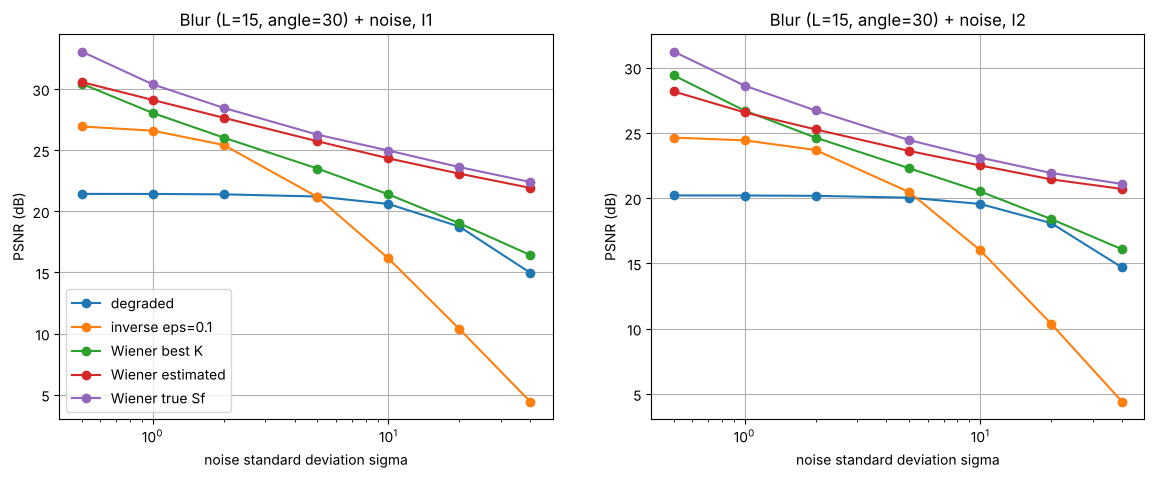

In [11]:
sigmas = [0.5, 1, 2, 5, 10, 20, 40]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for i, (f_, H_, name) in enumerate([(f, H, "I1"), (f2, H_2, "I2")]):
    curves = {"degraded": [], "inverse eps=0.1": [], "Wiener best K": [],
              "Wiener estimated": [], "Wiener true Sf": []}

    for s in sigmas:
        g = r.add_noise(r.blur(f_, H_), s, rng)
        best = max(K_values, key=lambda K: r.psnr(f_, r.wiener_filter(g, H_, K)))
        s_hat = r.estimate_sigma(g)
        Sf_est, _ = r.estimate_Sf(g, H_, s_hat)

        curves["degraded"].append(r.psnr(f_, g))
        curves["inverse eps=0.1"].append(r.psnr(f_, r.inverse_filter(g, H_, 0.1)))
        curves["Wiener best K"].append(r.psnr(f_, r.wiener_filter(g, H_, best)))
        curves["Wiener estimated"].append(r.psnr(f_, r.wiener_filter(g, H_, s_hat ** 2 / Sf_est)))
        curves["Wiener true Sf"].append(r.psnr(f_, r.wiener_filter(g, H_, r.true_nsr(f_, s))))

    for label in curves:
        ax[i].semilogx(sigmas, curves[label], "o-", label=label)
    ax[i].set_xlabel("noise standard deviation sigma")
    ax[i].set_ylabel("PSNR (dB)")
    ax[i].set_title(f"Blur (L={L}, angle={ANGLE}) + noise, {name}")
    ax[i].grid(True)
ax[0].legend()
plt.show()

**Observations.** Without noise the inverse filter (with a tiny threshold) is best. With noise it gets worse than doing nothing, because it amplifies the noise where $|H|$ is small. A constant $K$ helps only a little: it assumes a flat image spectrum, but image power drops by orders of magnitude towards high frequencies. The Wiener filter with the estimated power-law spectrum needs only $g$ and $h$, and gets within about 0.5–2 dB of the Wiener filter that knows the true spectrum.

## 9. Different blur lengths and angles (blur + noise)
Same comparison as in section 7, but now for several blur lengths $L$ (angle fixed) and several angles (length fixed), with $\sigma = 10$.

In [12]:
# Restore g with every filter and return the PSNR of each result
def compare_filters(f, g, H, sigma):
    best_K = max(K_values, key=lambda K: r.psnr(f, r.wiener_filter(g, H, K)))
    s_hat = r.estimate_sigma(g)
    Sf_est, _ = r.estimate_Sf(g, H, s_hat)
    return {
        "degraded": r.psnr(f, g),
        "inverse eps=0.1": r.psnr(f, r.inverse_filter(g, H, 0.1)),
        "Wiener best K": r.psnr(f, r.wiener_filter(g, H, best_K)),
        "Wiener estimated": r.psnr(f, r.wiener_filter(g, H, s_hat ** 2 / Sf_est)),
        "Wiener true Sf": r.psnr(f, r.wiener_filter(g, H, r.true_nsr(f, sigma))),
    }

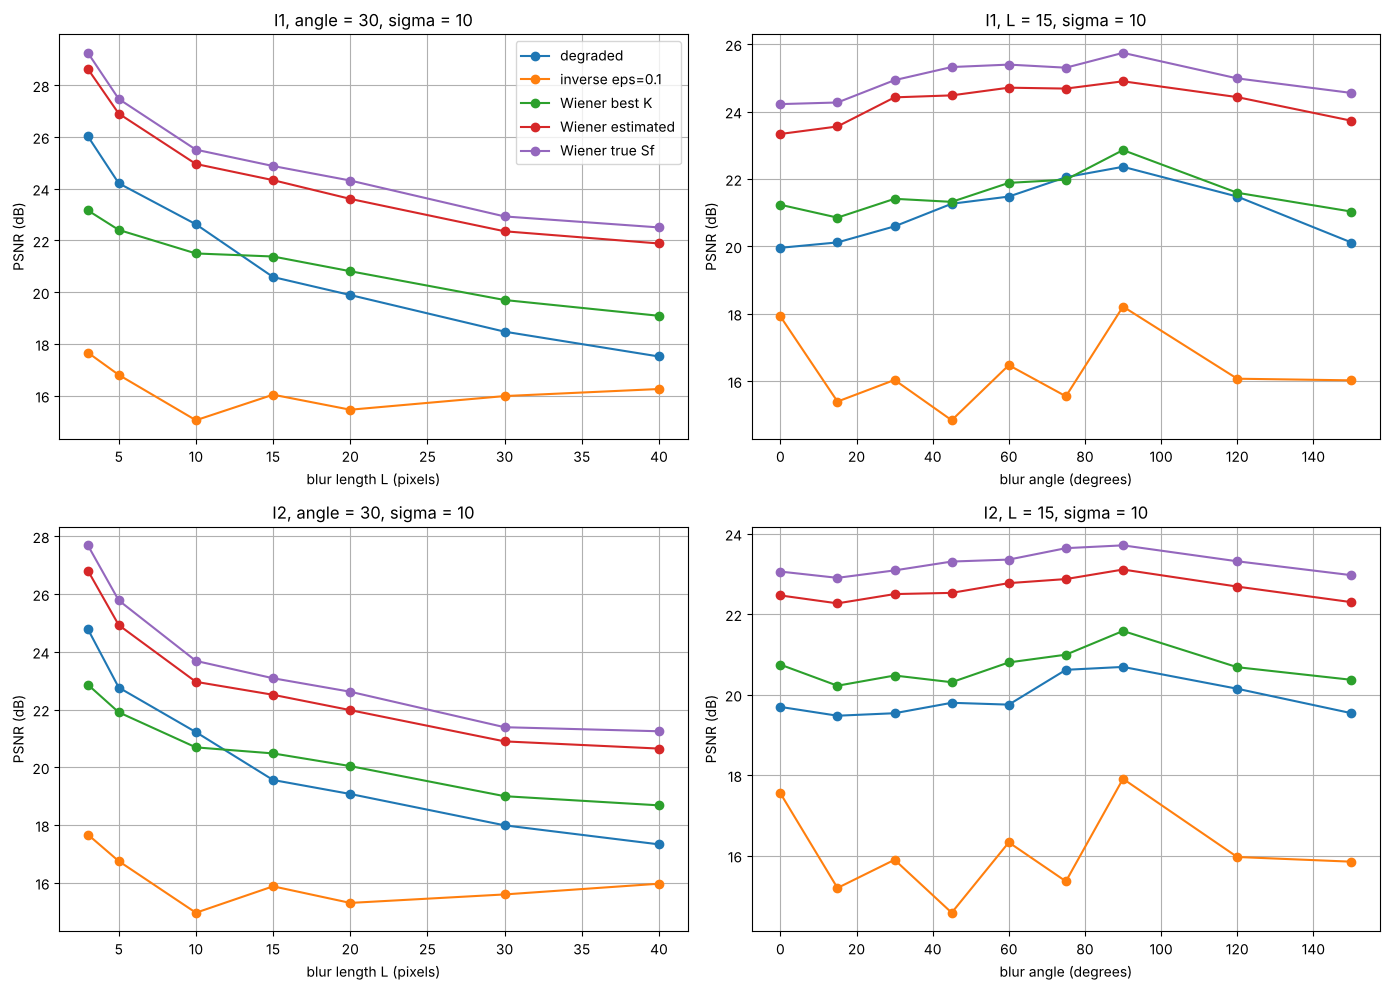

In [13]:
lengths = [3, 5, 10, 15, 20, 30, 40]
angles = [0, 15, 30, 45, 60, 75, 90, 120, 150]
results_L = {}
results_A = {}
for f_, name in [(f, "I1"), (f2, "I2")]:
    results_L[name] = {}
    for length in lengths:
        H_L = np.fft.fft2(r.motion_psf(length, ANGLE, f_.shape))
        g = r.add_noise(r.blur(f_, H_L), SIGMA, rng)
        results_L[name][length] = compare_filters(f_, g, H_L, SIGMA)

    results_A[name] = {}
    for angle in angles:
        H_A = np.fft.fft2(r.motion_psf(L, angle, f_.shape))
        g = r.add_noise(r.blur(f_, H_A), SIGMA, rng)
        results_A[name][angle] = compare_filters(f_, g, H_A, SIGMA)

fig, ax = plt.subplots(2, 2, figsize=(14, 10))
for row, name in enumerate(results_L):
    for label in results_L[name][lengths[0]]:
        ax[row, 0].plot(lengths, [results_L[name][x][label] for x in lengths], "o-", label=label)
        ax[row, 1].plot(angles, [results_A[name][x][label] for x in angles], "o-", label=label)
    ax[row, 0].set_xlabel("blur length L (pixels)")
    ax[row, 0].set_title(f"{name}, angle = {ANGLE}, sigma = {SIGMA}")
    ax[row, 1].set_xlabel("blur angle (degrees)")
    ax[row, 1].set_title(f"{name}, L = {L}, sigma = {SIGMA}")
for a in ax.flat:
    a.set_ylabel("PSNR (dB)")
    a.grid(True)
ax[0, 0].legend()
plt.tight_layout()
plt.show()

In [14]:
for name in results_L:
    print(name)
    print(f"{'L':>4}" + "".join(f"{label:>18}" for label in results_L[name][lengths[0]]))
    for length in lengths:
        print(f"{length:>4}" + "".join(f"{v:>18.2f}" for v in results_L[name][length].values()))
    print()

I1
   L          degraded   inverse eps=0.1     Wiener best K  Wiener estimated    Wiener true Sf
   3             26.03             17.67             23.16             28.63             29.25
   5             24.21             16.80             22.41             26.90             27.47
  10             22.63             15.05             21.50             24.96             25.51
  15             20.59             16.04             21.38             24.33             24.88
  20             19.89             15.46             20.81             23.61             24.32
  30             18.47             15.98             19.70             22.36             22.93
  40             17.51             16.26             19.09             21.88             22.50

I2
   L          degraded   inverse eps=0.1     Wiener best K  Wiener estimated    Wiener true Sf
   3             24.78             17.67             22.86             26.81             27.69
   5             22.76             16.75   

**Observations.**
* The degraded image and both spectrum-based Wiener filters get worse as $L$ grows: a longer blur removes more frequencies, and no linear filter can bring those back.
* The ranking of the Wiener filters is the same for every length: true spectrum > estimated spectrum > constant $K$. For short blurs ($L \le 10$) the constant-$K$ Wiener filter and the inverse filter are even worse than doing nothing.
* The inverse filter stays around 15–18 dB for every length: with a fixed $\varepsilon = 0.1$ it is always dominated by amplified noise.
* The angle changes the results by about 2 dB. The blur removes detail in the direction of motion, so the result depends on how much detail the image has in that direction. Vertical motion (90°) does the least damage to I1, probably because it has many vertical edges (blurring along an edge barely changes it). The irregular inverse-filter curve comes from where the near-zeros of $|H|$ fall after rounding the line to pixels.

## 10. Restoring with a wrongly assumed blur kernel

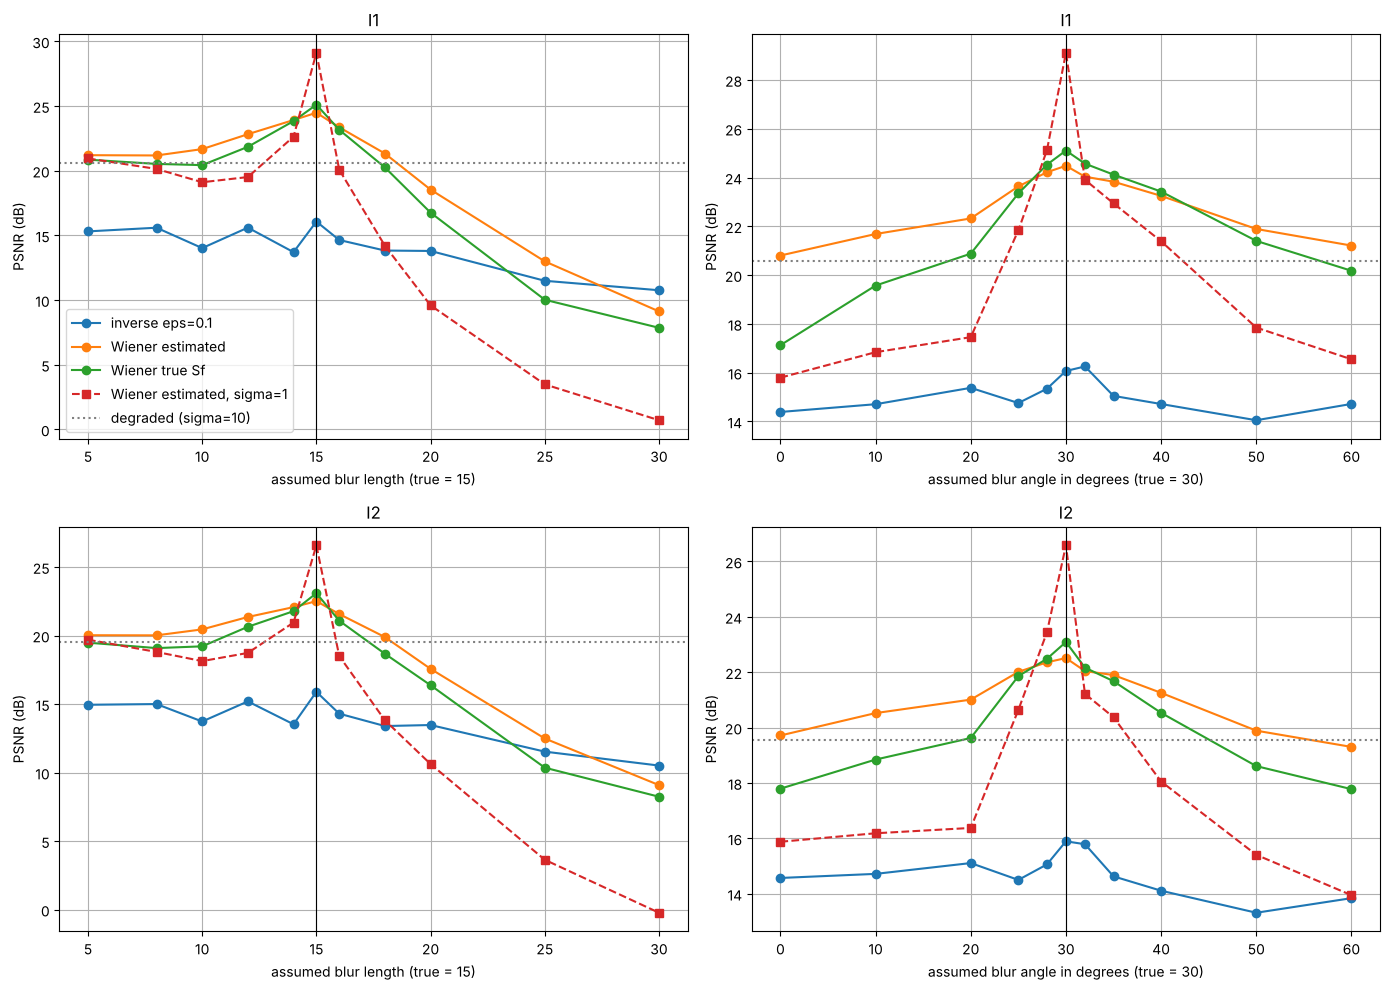

In [15]:
def restore_with_kernel(f, g, H_assumed, sigma):
    s_hat = r.estimate_sigma(g)
    Sf_est, _ = r.estimate_Sf(g, H_assumed, s_hat)
    return {
        "inverse eps=0.1": r.inverse_filter(g, H_assumed, 0.1),
        "Wiener estimated": r.wiener_filter(g, H_assumed, s_hat ** 2 / Sf_est),
        "Wiener true Sf": r.wiener_filter(g, H_assumed, r.true_nsr(f, sigma)),
    }

assumed_lengths = [5, 8, 10, 12, 14, 15, 16, 18, 20, 25, 30]
assumed_angles = [0, 10, 20, 25, 28, 30, 32, 35, 40, 50, 60]
g_low = {}
g_high = {}

fig, ax = plt.subplots(2, 2, figsize=(14, 10))
for row, (f_, H_, name) in enumerate([(f, H, "I1"), (f2, H_2, "I2")]):
    g_low[name] = r.add_noise(r.blur(f_, H_), 1, rng)          # little noise (sigma = 1)
    g_high[name] = r.add_noise(r.blur(f_, H_), SIGMA, rng)     # sigma = 10

    # Wrong length (angle correct)
    psnr_wrong_L = {"inverse eps=0.1": [], "Wiener estimated": [], "Wiener true Sf": [],
                    "Wiener estimated, sigma=1": []}
    for length in assumed_lengths:
        H_guess = np.fft.fft2(r.motion_psf(length, ANGLE, f_.shape))
        res = restore_with_kernel(f_, g_high[name], H_guess, SIGMA)
        for label in res:
            psnr_wrong_L[label].append(r.psnr(f_, res[label]))
        res_low = restore_with_kernel(f_, g_low[name], H_guess, 1)
        psnr_wrong_L["Wiener estimated, sigma=1"].append(r.psnr(f_, res_low["Wiener estimated"]))

    # Wrong angle (length correct)
    psnr_wrong_A = {"inverse eps=0.1": [], "Wiener estimated": [], "Wiener true Sf": [],
                    "Wiener estimated, sigma=1": []}
    for angle in assumed_angles:
        H_guess = np.fft.fft2(r.motion_psf(L, angle, f_.shape))
        res = restore_with_kernel(f_, g_high[name], H_guess, SIGMA)
        for label in res:
            psnr_wrong_A[label].append(r.psnr(f_, res[label]))
        res_low = restore_with_kernel(f_, g_low[name], H_guess, 1)
        psnr_wrong_A["Wiener estimated, sigma=1"].append(r.psnr(f_, res_low["Wiener estimated"]))

    for label in psnr_wrong_L:
        style = "s--" if "sigma=1" in label else "o-"
        ax[row, 0].plot(assumed_lengths, psnr_wrong_L[label], style, label=label)
        ax[row, 1].plot(assumed_angles, psnr_wrong_A[label], style, label=label)
    ax[row, 0].axvline(L, color="k", lw=0.8)
    ax[row, 1].axvline(ANGLE, color="k", lw=0.8)
    ax[row, 0].axhline(r.psnr(f_, g_high[name]), color="gray", ls=":", label="degraded (sigma=10)")
    ax[row, 1].axhline(r.psnr(f_, g_high[name]), color="gray", ls=":")
    ax[row, 0].set_xlabel("assumed blur length (true = 15)")
    ax[row, 1].set_xlabel("assumed blur angle in degrees (true = 30)")
    ax[row, 0].set_title(name)
    ax[row, 1].set_title(name)
for a in ax.flat:
    a.set_ylabel("PSNR (dB)")
    a.grid(True)
ax[0, 0].legend()
plt.tight_layout()
plt.show()

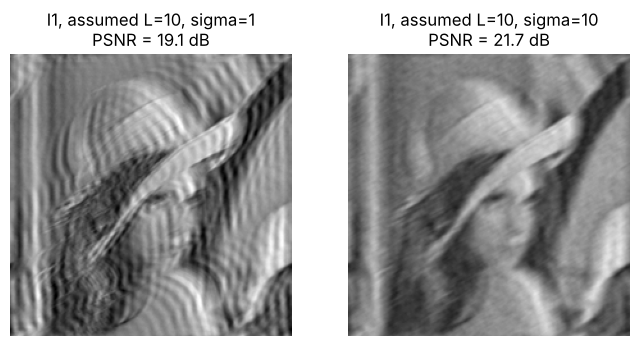

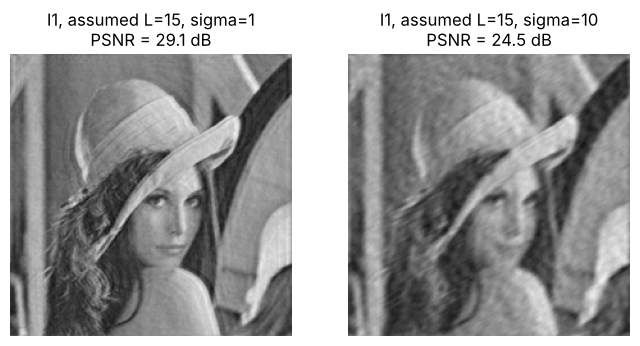

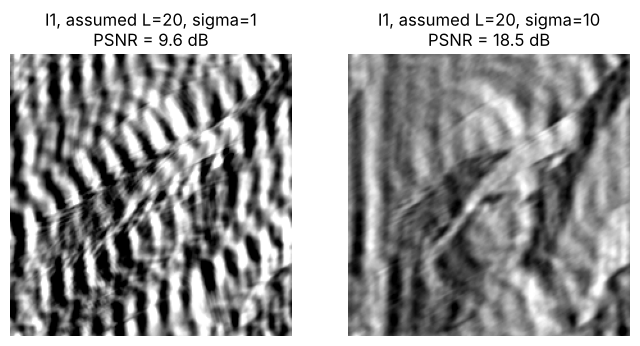

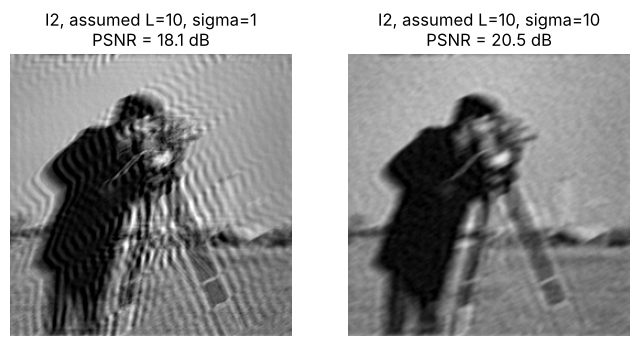

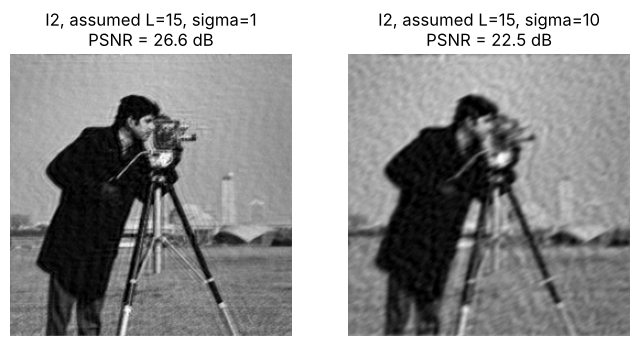

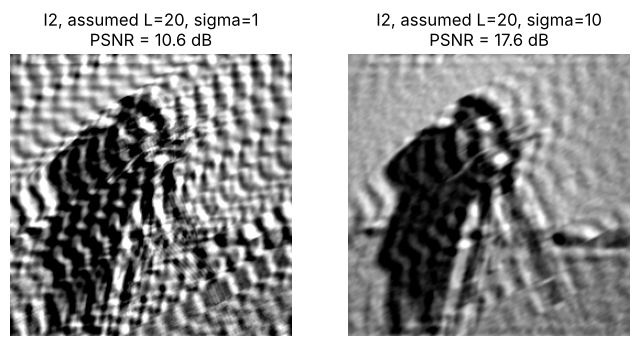

In [16]:
for f_, name in [(f, "I1"), (f2, "I2")]:
    for length in [10, 15, 20]:
        H_guess = np.fft.fft2(r.motion_psf(length, ANGLE, f_.shape))
        show(f_, {f"{name}, assumed L={length}, sigma=1": restore_with_kernel(f_, g_low[name], H_guess, 1)["Wiener estimated"],
                  f"{name}, assumed L={length}, sigma=10": restore_with_kernel(f_, g_high[name], H_guess, SIGMA)["Wiener estimated"]})

**Observations.**
* Every curve peaks at the true kernel ($L=15$, $30°$). A wrong kernel always costs PSNR.
* With little noise ($\sigma=1$) the filter is very sensitive: 1 pixel wrong in length drops I1 from 29 to about 21 dB, and 2° wrong in angle drops it to about 24-25 dB. The zeros of the assumed $H$ are in the wrong place, so the filter boosts frequencies that were not attenuated, and gives ringing.
* With more noise ($\sigma=10$) the Wiener filter boosts less, so it is more forgiving: the curves are much flatter.
* Assuming a too long blur is worse than a too short one: for $L \ge 20$ the result is worse than the degraded image (with $L=30$ it falls to about 0-9 dB). A too short kernel just restores less.

## 11. Realistic blur at the borders: edge tapering and padding
So far the blur was circular, which matches the DFT exactly. A real camera does not wrap around: pixels near the border are mixed with the scene outside the image. `blur_realistic` imitates this by padding with border pixels, blurring and cropping. Now $G = HF + N$ no longer holds near the borders, and the jump between the left and right (top and bottom) edge of the periodic image puts strong vertical/horizontal lines in the spectrum. After deblurring this shows up as ringing over the whole image.

Two fixes (the 2-D version of windowing a 1-D signal before the FFT):
* **taper**: fade the image to its mean near the borders with a cosine window, so the periodic image has no jump.
* **pad + taper**: first pad the image by `PAD` pixels (repeat the border), then taper only the padding, and crop after filtering. The real image is then not changed by the window.

The table shows PSNR over the whole image and over the centre (border of `PAD` pixels removed).

In [17]:
PAD = 20
center = slice(PAD, -PAD)

def restore_estimated(g, H):
    s_hat = r.estimate_sigma(g)
    Sf_est, _ = r.estimate_Sf(g, H, s_hat)
    return r.wiener_filter(g, H, s_hat ** 2 / Sf_est)

def restore_pad_taper(g, length, angle):
    g_big = r.taper_edges(np.pad(g, PAD, mode="edge"), PAD)
    H_big = np.fft.fft2(r.motion_psf(length, angle, g_big.shape))
    return restore_estimated(g_big, H_big)[PAD:-PAD, PAD:-PAD]

print(f"{'image':<6}{'sigma':>6}{'degraded':>10}{'no fix':>16}{'taper':>16}{'pad + taper':>16}{'circular blur':>15}")
print(f"{'':<6}{'':>6}{'':>10}{'(all / centre)':>16}{'(all / centre)':>16}{'(all / centre)':>16}{'(reference)':>15}")
for name in images:
    f_ = images[name]
    H_ = np.fft.fft2(r.motion_psf(L, ANGLE, f_.shape))
    for s in [1, 10]:
        g = r.add_noise(r.blur_realistic(f_, L, ANGLE), s, rng)
        no_fix = restore_estimated(g, H_)
        tapered = restore_estimated(r.taper_edges(g, PAD), H_)
        padded = restore_pad_taper(g, L, ANGLE)
        circular = restore_estimated(r.add_noise(r.blur(f_, H_), s, rng), H_)
        row = f"{name:<6}{s:>6}{r.psnr(f_, g):>10.2f}"
        for res in [no_fix, tapered, padded]:
            row += f"{r.psnr(f_, res):>9.2f} /{r.psnr(f_[center, center], res[center, center]):>5.1f}"
        print(row + f"{r.psnr(f_, circular):>15.2f}")

image  sigma  degraded          no fix           taper     pad + taper  circular blur
                        (all / centre)  (all / centre)  (all / centre)    (reference)
I1         1     21.79    13.89 / 15.0    21.28 / 24.9    24.48 / 24.7          29.09
I1        10     20.87    21.51 / 23.3    21.24 / 23.8    23.54 / 23.2          24.44


I2         1     20.28    20.64 / 23.4    22.68 / 25.6    26.02 / 25.9          26.59
I2        10     19.61    22.23 / 21.8    20.92 / 22.0    22.39 / 21.9          22.52


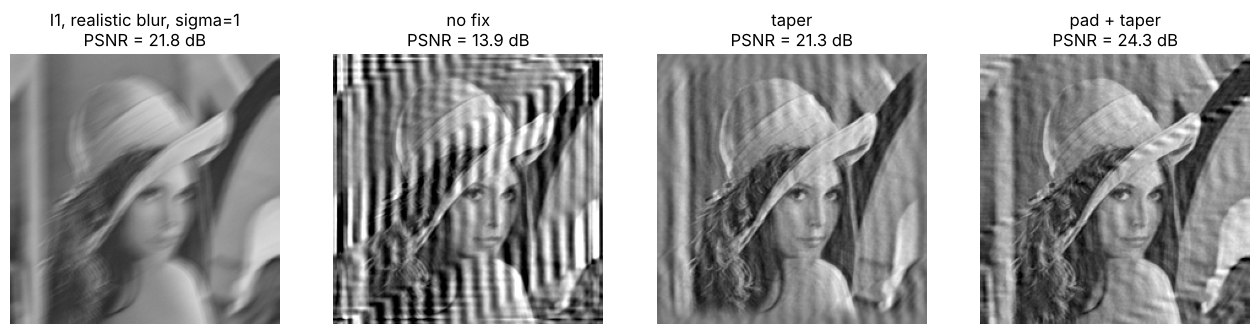

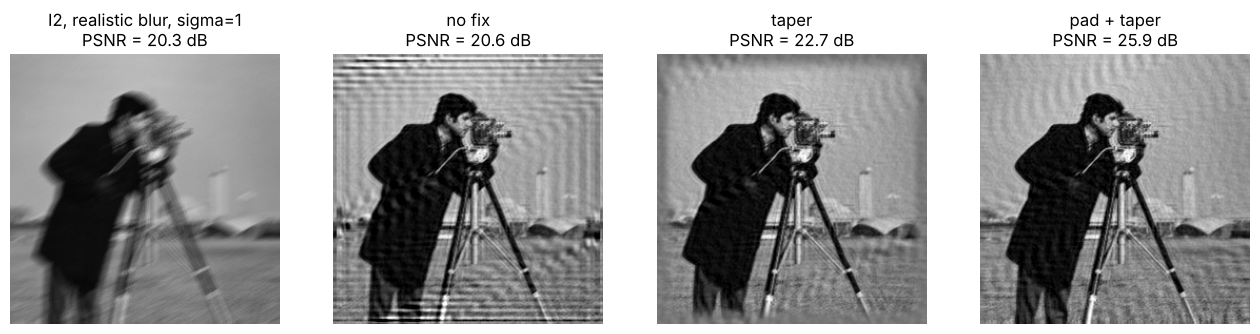

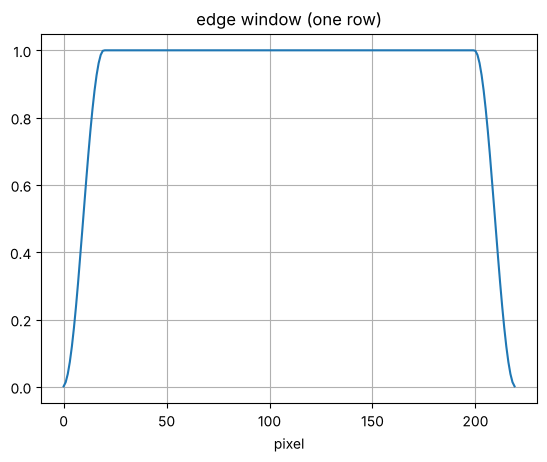

In [18]:
for f_, H_, name in [(f, H, "I1"), (f2, H_2, "I2")]:
    g_real = r.add_noise(r.blur_realistic(f_, L, ANGLE), 1, rng)
    show(f_, {f"{name}, realistic blur, sigma=1": g_real,
              "no fix": restore_estimated(g_real, H_),
              "taper": restore_estimated(r.taper_edges(g_real, PAD), H_),
              "pad + taper": restore_pad_taper(g_real, L, ANGLE)})

plt.plot(r.edge_window(f.shape[1], PAD))
plt.title("edge window (one row)")
plt.xlabel("pixel")
plt.grid(True)
plt.show()

**Observations** 
* The image where padding + tapering is performed, has a better PSNR, though it is not immediately obvious if they "look better" than realistic blur and tapering only. PSNR is just the average squared pixel error, and it doesn't match how images look. Deblurring boosts high frequencies, so it also gets ringing (ripples next to edges),
* Could also look at SSIM as a metric (structural similarity). It compares local mean, contrast and structure in small windows, and it penalises ringing and noise texture more like a viewer would.

## 12. Summary

**Which filter works best when**
* **Blur only:** the inverse filter with a tiny threshold ($\varepsilon \approx 0.001$) gives 42-48 dB, and the Wiener filter with the best (tiny) $K$ even 51-55 dB. The estimated Wiener filter only reaches about 32 dB here. The main reason is the noise estimate: on a blurred image without noise, image detail does not cancel completely in the pixel differences, so $\hat\sigma \approx 0.4$-$0.6$ instead of 0. The filter then assumes there is noise and does not invert the frequencies where $|H|$ is small. With the same estimated $S_f$ and $\sigma \approx 0$ it reaches about 55 dB.
* **Noise only:** $H=1$, so the inverse filter does nothing. The Wiener filter with a spectrum (estimated or true) is the only one that helps (about +2-4 dB); a constant $K$ barely does anything.
* **Blur + noise:** the inverse filter is worse than the degraded image. The Wiener filter with the estimated power-law spectrum is best in practice, within about 0.5-2 dB of the Wiener filter that knows the true spectrum.

**Problems we had and how we solved them**
1. $H$ has (near-)zeros, so $G/H$ divides by zero: threshold $\varepsilon$ in the inverse filter, $+S_n/S_f$ in the Wiener filter.
2. Noise is amplified where $|H|$ is small: Wiener filter instead of inverse filter.
3. $\sigma$ and $S_f$ are unknown in practice: $\sigma$ from the median of pixel differences, $S_f$ from a power-law fit to the smoothed periodogram of $g$.
4. The periodogram has a very high variance: $5\times5$ averaging, and only 2 parameters are fitted.
5. A constant $K$ ignores that image power drops with frequency: use the estimated $S_f(u,v)$.
6. Real blur is not circular, which gives ringing from the borders: pad + taper the edges.
7. The kernel must be known exactly, especially at low noise (section 10).